# EDA — Building Data Genome 2 (Task 1, bước 2)

Khám phá toàn bộ dữ liệu BDG2 trên **tầng Bronze** bằng Spark, để đưa ra các **quyết định làm sạch có số liệu** cho bước Silver (`data_pipeline/preprocess.py`).

Chạy trước: `python data_pipeline/ingest.py`. Mọi phép tính nặng chạy bằng Spark; chỉ kết quả đã tổng hợp (vài chục dòng) mới chuyển sang pandas để hiển thị và vẽ.

| Mục | Câu hỏi |
|---|---|
| 0 | Chuẩn bị: đọc Bronze, xoay 8 bảng đồng hồ sang dạng long |
| 1 | Tổng quan: bao nhiêu tòa nhà, site, đồng hồ, bản ghi? |
| 2 | Metadata: thiếu gì, múi giờ của từng site |
| 3 | Dữ liệu thiếu (null) theo loại đồng hồ, tòa nhà, site |
| 4 | Giá trị bất thường: số âm, số 0, flatline, outlier |
| 5 | Thời tiết: thiếu dữ liệu, trùng lặp, độ phủ |
| 6 | Timestamp là giờ địa phương hay UTC? |
| 7 | Quy luật tiêu thụ: theo giờ, cuối tuần, nhiệt độ |
| 8 | Tổng hợp quyết định làm sạch |

## 0. Chuẩn bị

In [1]:
import os

os.environ.setdefault("SPARK_DRIVER_MEMORY", "6g")

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import Window
from pyspark.sql import functions as F

from common.config import BRONZE_DIR, DATA_DIR
from common.spark_session import build_spark

spark = build_spark("bdg2_eda")
spark.sparkContext.setLogLevel("ERROR")
pd.set_option("display.float_format", "{:,.2f}".format)

METERS = ["electricity", "chilledwater", "steam", "hotwater", "gas", "water", "irrigation", "solar"]
LINEAGE = ["_source_file", "_ingested_at"]


def bronze(name):
    return spark.read.format("delta").load(f"{BRONZE_DIR}/{name}")

In [2]:
# Chart style: one validated categorical order, recessive grid/axes, 2px lines.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})

**Xoay bảng (unpivot).** Mỗi file đồng hồ ở dạng *wide*: 1 cột `timestamp` + 1 cột cho mỗi tòa nhà. Để phân tích theo tòa nhà, xoay sang dạng *long* `(meter_type, building_id, timestamp, meter_reading)` rồi gộp 8 loại đồng hồ.

Lưu ý: 29 đồng hồ **hoàn toàn trống** (100% null) nên Spark suy ra kiểu chuỗi ở Bronze; khi xoay bảng, mọi cột tòa nhà được ép về `double`.

Bảng long được ghi tạm ra `data/eda/meters_long` (không phải tầng chính thức của pipeline, chỉ để các truy vấn EDA bên dưới chạy nhanh, không phải xoay lại mỗi lần).

In [3]:
import time

LONG_PATH = str(DATA_DIR / "eda" / "meters_long")
t0 = time.perf_counter()
parts = []
for m in METERS:
    wide = bronze(m).drop(*LINEAGE)
    buildings = [c for c in wide.columns if c != "timestamp"]
    # Columns that are 100% empty were inferred as string in Bronze; cast all to double.
    wide = wide.select("timestamp", *[F.col(c).cast("double").alias(c) for c in buildings])
    parts.append(
        wide.unpivot("timestamp", buildings, "building_id", "meter_reading")
        .withColumn("meter_type", F.lit(m))
    )
long_df = parts[0]
for p in parts[1:]:
    long_df = long_df.unionByName(p)
long_df.write.format("delta").mode("overwrite").partitionBy("meter_type").save(LONG_PATH)

meters = spark.read.format("delta").load(LONG_PATH)
print(f"{meters.count():,} bản ghi — {time.perf_counter() - t0:.0f}s")

53,561,832 bản ghi — 38s


## 1. Tổng quan

In [4]:
overview = (
    meters.groupBy("meter_type")
    .agg(
        F.countDistinct("building_id").alias("buildings"),
        F.count("*").alias("records"),
        F.avg(F.col("meter_reading").isNull().cast("int")).alias("null_pct"),
        F.avg((F.col("meter_reading") == 0).cast("int")).alias("zero_pct"),
        F.sum((F.col("meter_reading") < 0).cast("int")).alias("negatives"),
        F.min("timestamp").alias("first"),
        F.max("timestamp").alias("last"),
    )
    .orderBy(F.desc("records"))
    .toPandas()
)
overview[["null_pct", "zero_pct"]] *= 100
total = overview[["buildings", "records", "negatives"]].sum()
print(f"Tổng: {total.records:,} bản ghi, {total.buildings:,} đồng hồ, {total.negatives:,} giá trị âm")
overview

Tổng: 53,561,832 bản ghi, 3,053 đồng hồ, 0 giá trị âm


,meter_type,buildings,records,null_pct,zero_pct,negatives,first,last
0,electricity,1578,27684432,4.74,4.40,0,2016-01-01,2017-12-31 23:00:00
1,chilledwater,555,9736920,6.95,17.77,0,2016-01-01,2017-12-31 23:00:00
2,steam,370,6491280,11.26,14.46,0,2016-01-01,2017-12-31 23:00:00
3,hotwater,185,3245640,6.20,35.12,0,2016-01-01,2017-12-31 23:00:00
4,gas,177,3105288,3.34,39.06,0,2016-01-01,2017-12-31 23:00:00
5,water,146,2561424,5.78,51.05,0,2016-01-01,2017-12-31 23:00:00
6,irrigation,37,649128,10.70,85.80,0,2016-01-01,2017-12-31 23:00:00
7,solar,5,87720,20.13,34.04,0,2016-01-01,2017-12-31 23:00:00


## 2. Metadata

In [5]:
meta = bronze("metadata")
print("Số tòa nhà:", meta.count(), "| số site:", meta.select("site_id").distinct().count())
meta.select(
    F.sum(F.col("primaryspaceusage").isNull().cast("int")).alias("thiếu primary_use"),
    F.sum(F.col("sqft").isNull().cast("int")).alias("thiếu sqft"),
    F.sum(F.col("timezone").isNull().cast("int")).alias("thiếu timezone"),
    F.sum(F.col("lat").isNull().cast("int")).alias("thiếu lat/lng"),
).toPandas()

Số tòa nhà: 1636 | số site: 19


,thiếu primary_use,thiếu sqft,thiếu timezone,thiếu lat/lng
0,21,0,0,237


In [6]:
(
    meta.groupBy("primaryspaceusage").count().orderBy(F.desc("count"))
    .withColumnRenamed("primaryspaceusage", "primary_use").toPandas()
)

,primary_use,count
0,Education,617
1,Office,307
2,Entertainment/public assembly,204
3,Lodging/residential,168
4,Public services,166
5,Healthcare,29
6,Other,29
7,Parking,24
8,None,21
9,Warehouse/storage,15


In [7]:
# Múi giờ theo site: mỗi site phải có đúng 1 múi giờ thì mới chuyển sang UTC được.
site_tz = (
    meta.groupBy("site_id")
    .agg(
        F.count("*").alias("buildings"),
        F.collect_set("timezone").alias("timezones"),
        F.sum(F.col("primaryspaceusage").isNull().cast("int")).alias("missing_use"),
    )
    .orderBy("site_id")
    .toPandas()
)
site_tz

,site_id,buildings,timezones,missing_use
0,Bear,92,[US/Pacific],0
1,Bobcat,36,[US/Mountain],0
2,Bull,124,[US/Central],0
3,Cockatoo,124,[US/Eastern],0
4,Crow,5,[US/Eastern],0
5,Eagle,106,[US/Eastern],0
6,Fox,137,[US/Mountain],0
7,Gator,74,[US/Eastern],0
8,Hog,163,[US/Central],0
9,Lamb,147,[Europe/London],0


## 3. Dữ liệu thiếu (null)

In [8]:
per_building = (
    meters.groupBy("meter_type", "building_id")
    .agg(F.avg(F.col("meter_reading").isNull().cast("int")).alias("null_rate"))
)
null_buckets = (
    per_building.withColumn(
        "bucket",
        F.when(F.col("null_rate") == 0, "0%")
        .when(F.col("null_rate") <= 0.1, "≤10%")
        .when(F.col("null_rate") <= 0.5, "10–50%")
        .when(F.col("null_rate") < 1, "50–<100%")
        .otherwise("100%"),
    )
    .groupBy("meter_type").pivot("bucket", ["0%", "≤10%", "10–50%", "50–<100%", "100%"]).count()
    .fillna(0).toPandas().set_index("meter_type")
)
null_buckets

,0%,≤10%,10–50%,50–<100%,100%
meter_type,,,,,
solar,0,4,0,0,1
irrigation,0,24,12,1,0
gas,97,72,1,7,0
water,0,130,12,2,2
hotwater,43,118,6,18,0
chilledwater,155,324,40,31,5
electricity,373,1072,69,62,2
steam,105,214,17,15,19


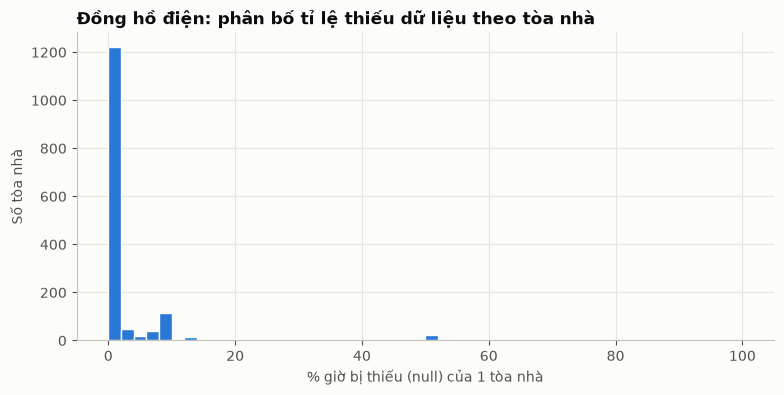

In [9]:
elec_null = per_building.filter("meter_type = 'electricity'").select("null_rate").toPandas()
fig, ax = plt.subplots()
ax.hist(elec_null.null_rate * 100, bins=50, color=SERIES[0], edgecolor="#fcfcfb", linewidth=1)
ax.set_title("Đồng hồ điện: phân bố tỉ lệ thiếu dữ liệu theo tòa nhà")
ax.set_xlabel("% giờ bị thiếu (null) của 1 tòa nhà")
ax.set_ylabel("Số tòa nhà")
plt.show()

In [10]:
# Thiếu theo site (điện): site nào thiếu nặng?
(
    meters.filter("meter_type = 'electricity'")
    .join(meta.select("building_id", "site_id"), "building_id")
    .groupBy("site_id")
    .agg(
        F.countDistinct("building_id").alias("buildings"),
        F.avg(F.col("meter_reading").isNull().cast("int")).alias("null_pct"),
    )
    .withColumn("null_pct", F.col("null_pct") * 100)
    .orderBy(F.desc("null_pct"))
    .toPandas()
)

,site_id,buildings,null_pct
0,Swan,19,50.13
1,Bobcat,35,25.38
2,Peacock,45,12.42
3,Cockatoo,117,9.17
4,Gator,74,9.05
5,Crow,5,7.85
6,Rat,305,7.58
7,Moose,13,4.37
8,Bear,92,3.61
9,Eagle,106,2.25


## 4. Giá trị bất thường

### 4.1. Số âm

In [11]:
(
    meters.filter("meter_reading < 0")
    .groupBy("meter_type", "building_id")
    .agg(F.count("*").alias("negatives"), F.min("meter_reading").alias("min_value"))
    .orderBy(F.desc("negatives"))
    .toPandas()
)

,meter_type,building_id,negatives,min_value


### 4.2. Flatline (giá trị đứng yên)

Một đoạn flatline là chuỗi giờ liên tiếp của 1 đồng hồ có **cùng một giá trị**. Đồng hồ hoạt động bình thường hiếm khi cho ra đúng một số qua nhiều giờ, nên đoạn dài thường là lỗi truyền dữ liệu hoặc giá trị bị điền sẵn.

Cách tính bằng Spark window: so mỗi giờ với giờ trước (`lag`), đánh dấu chỗ giá trị đổi, cộng dồn để ra mã đoạn, rồi đếm độ dài mỗi đoạn.

In [12]:
w = Window.partitionBy("meter_type", "building_id").orderBy("timestamp")
runs = (
    meters.withColumn("prev", F.lag("meter_reading").over(w))
    .withColumn("new_run", F.when(F.col("prev").eqNullSafe(F.col("meter_reading")), 0).otherwise(1))
    .withColumn("run_id", F.sum("new_run").over(w))
    .groupBy("meter_type", "building_id", "run_id")
    .agg(F.count("*").alias("hours"), F.first("meter_reading").alias("value"))
    .filter(F.col("value").isNotNull())
    .withColumn("is_zero", F.col("value") == 0)
    .cache()
)

BUCKETS = [(1, "1 giờ"), (6, "2–5 giờ"), (12, "6–11 giờ"), (24, "12–23 giờ"), (48, "24–47 giờ"),
           (168, "48 giờ–1 tuần"), (None, "≥ 1 tuần")]
bucket_col = F.lit(BUCKETS[-1][1])
for upper, label in reversed(BUCKETS[:-1]):
    bucket_col = F.when(F.col("hours") < upper, label).otherwise(bucket_col)
bucket_col = F.when(F.col("hours") == 1, "1 giờ").otherwise(bucket_col)

flat = (
    runs.filter("meter_type = 'electricity'")
    .withColumn("run_length", bucket_col)
    .groupBy("run_length", "is_zero")
    .agg(F.sum("hours").alias("hours"))
    .toPandas()
    .pivot(index="run_length", columns="is_zero", values="hours")
    .reindex([b[1] for b in BUCKETS]).fillna(0)
    .rename(columns={False: "giá trị khác 0", True: "giá trị 0"})
)
flat_pct = flat / flat.values.sum() * 100
flat_pct

is_zero,giá trị khác 0,giá trị 0
run_length,,
1 giờ,81.77,0.07
2–5 giờ,5.69,0.10
6–11 giờ,0.55,0.11
12–23 giờ,0.29,0.23
24–47 giờ,3.52,0.15
48 giờ–1 tuần,0.85,0.23
≥ 1 tuần,2.93,3.50


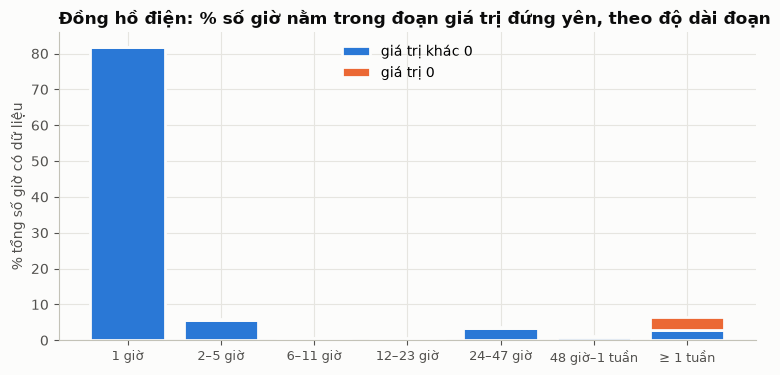

In [13]:
fig, ax = plt.subplots()
x = range(len(flat_pct))
ax.bar(x, flat_pct["giá trị khác 0"], width=0.8, color=SERIES[0], label="giá trị khác 0",
       edgecolor="#fcfcfb", linewidth=2)
ax.bar(x, flat_pct["giá trị 0"], width=0.8, bottom=flat_pct["giá trị khác 0"], color=SERIES[1],
       label="giá trị 0", edgecolor="#fcfcfb", linewidth=2)
ax.set_xticks(list(x), flat_pct.index, rotation=0, fontsize=9)
ax.set_title("Đồng hồ điện: % số giờ nằm trong đoạn giá trị đứng yên, theo độ dài đoạn")
ax.set_ylabel("% tổng số giờ có dữ liệu")
ax.legend(loc="upper center")
plt.show()

In [14]:
# Từng ngưỡng flatline sẽ loại bao nhiêu % số giờ có dữ liệu (tất cả loại đồng hồ)?
total_hours = runs.groupBy("meter_type").agg(F.sum("hours").alias("total"))
thresholds = [6, 12, 24, 48, 168]
(
    runs.groupBy("meter_type")
    .agg(*[
        F.sum(F.when(F.col("hours") >= t, F.col("hours")).otherwise(0)).alias(f">= {t}h")
        for t in thresholds
    ])
    .join(total_hours, "meter_type")
    .select("meter_type", *[(F.col(f">= {t}h") / F.col("total") * 100).alias(f">= {t}h") for t in thresholds])
    .orderBy("meter_type")
    .toPandas()
    .set_index("meter_type")
)

,>= 6h,>= 12h,>= 24h,>= 48h,>= 168h
meter_type,,,,,
chilledwater,17.69,15.95,14.39,13.61,11.66
electricity,12.37,11.70,11.19,7.52,6.44
gas,37.53,32.24,25.85,23.93,17.55
hotwater,39.12,33.63,28.43,26.65,22.98
irrigation,80.10,75.04,60.51,47.60,17.31
solar,24.72,23.41,21.60,19.84,16.25
steam,12.47,10.65,8.91,8.03,6.43
water,41.29,32.16,21.85,16.60,9.70


In [15]:
# Riêng số 0: tòa nhà điện có bao nhiêu % giờ bằng 0? (đồng hồ chết hay tòa nhà thật sự không dùng?)
zero_rate = (
    meters.filter("meter_type = 'electricity' AND meter_reading IS NOT NULL")
    .groupBy("building_id")
    .agg(F.avg((F.col("meter_reading") == 0).cast("int")).alias("zero_rate"))
)
zero_rate.select(
    F.sum((F.col("zero_rate") == 0).cast("int")).alias("không có số 0"),
    F.sum(((F.col("zero_rate") > 0) & (F.col("zero_rate") <= 0.05)).cast("int")).alias("≤5%"),
    F.sum(((F.col("zero_rate") > 0.05) & (F.col("zero_rate") <= 0.5)).cast("int")).alias("5–50%"),
    F.sum((F.col("zero_rate") > 0.5).cast("int")).alias(">50%"),
).toPandas()

,không có số 0,≤5%,5–50%,>50%
0,570,723,261,22


### 4.3. Outlier (giá trị cực lớn)

So giá trị lớn nhất của mỗi đồng hồ với phân vị 99% (p99) của chính nó. Tỉ lệ `max / p99` rất lớn nghĩa là có vài giờ vọt lên bất thường (thường là lỗi đơn vị hoặc lỗi cộng dồn).

In [16]:
spikes = (
    meters.filter("meter_reading > 0")
    .groupBy("meter_type", "building_id")
    .agg(
        F.percentile_approx("meter_reading", 0.5).alias("p50"),
        F.percentile_approx("meter_reading", 0.99).alias("p99"),
        F.max("meter_reading").alias("max"),
    )
    .withColumn("max_over_p99", F.col("max") / F.col("p99"))
    .cache()
)
spikes.groupBy("meter_type").agg(
    F.count("*").alias("meters"),
    F.sum((F.col("max_over_p99") > 5).cast("int")).alias("max > 5×p99"),
    F.sum((F.col("max_over_p99") > 10).cast("int")).alias("max > 10×p99"),
    F.sum((F.col("max_over_p99") > 100).cast("int")).alias("max > 100×p99"),
).orderBy("meter_type").toPandas()

,meter_type,meters,max > 5×p99,max > 10×p99,max > 100×p99
0,chilledwater,547,73,42,1
1,electricity,1572,44,27,2
2,gas,176,3,0,0
3,hotwater,184,27,16,1
4,irrigation,32,1,0,0
5,solar,4,3,2,0
6,steam,348,76,50,0
7,water,130,19,4,0


In [17]:
spikes.orderBy(F.desc("max_over_p99")).limit(10).toPandas()

,meter_type,building_id,p50,p99,max,max_over_p99
0,electricity,Lamb_education_Willetta,0.00,0.00,17.84,"44,600.00"
1,electricity,Bull_education_Dottie,"1,359.00","1,655.00","221,228.00",133.67
2,chilledwater,Bull_education_Dottie,"11,954.02","26,493.87","2,752,416.88",103.89
3,hotwater,Bobcat_education_Dylan,378.61,929.52,"96,546.20",103.87
4,steam,Bull_lodging_Terence,12.09,36.28,"2,936.80",80.95
5,water,Bobcat_lodging_Darin,"1,135.62","3,406.88","254,756.66",74.78
6,steam,Bull_education_Clarice,30.70,104.19,"7,562.00",72.58
7,solar,Bobcat_other_Timothy,0.47,17.00,"1,229.13",72.30
8,steam,Hog_lodging_Mauricio,"1,057.97","3,517.03","228,750.00",65.04
9,steam,Bull_education_Dottie,273.49,840.02,"49,561.86",59.00


## 5. Thời tiết

In [18]:
weather = bronze("weather").drop(*LINEAGE)
value_cols = [c for c in weather.columns if c not in ("timestamp", "site_id")]
weather.select([
    (F.avg(F.col(c).isNull().cast("int")) * 100).alias(c) for c in value_cols
]).toPandas().T.rename(columns={0: "null_pct"})

,null_pct
airTemperature,0.04
cloudCoverage,51.63
dewTemperature,0.10
precipDepth1HR,40.22
precipDepth6HR,94.52
seaLvlPressure,6.53
windDirection,3.93
windSpeed,0.17


In [19]:
EXPECTED_HOURS = 2 * 365 * 24 + 24  # 2016 is a leap year -> 17,544
dups = weather.groupBy("site_id", "timestamp").count().filter("count > 1")
print("Cặp (site, giờ) bị trùng:", dups.count())
(
    weather.groupBy("site_id")
    .agg(
        F.countDistinct("timestamp").alias("hours"),
        (F.avg(F.col("airTemperature").isNull().cast("int")) * 100).alias("air_null_pct"),
        (F.avg(F.col("dewTemperature").isNull().cast("int")) * 100).alias("dew_null_pct"),
    )
    .withColumn("missing_hours", EXPECTED_HOURS - F.col("hours"))
    .orderBy(F.desc("missing_hours"))
    .toPandas()
)

Cặp (site, giờ) bị trùng: 0


,site_id,hours,air_null_pct,dew_null_pct,missing_hours
0,Crow,16860,0.00,0.27,684
1,Moose,16860,0.00,0.27,684
2,Cockatoo,16975,0.01,0.03,569
3,Lamb,17500,0.01,0.01,44
4,Wolf,17505,0.00,0.00,39
5,Shrew,17516,0.01,0.01,28
6,Robin,17516,0.01,0.01,28
7,Mouse,17516,0.01,0.01,28
8,Bobcat,17525,0.18,0.19,19
9,Bull,17529,0.19,0.73,15


## 6. Timestamp là giờ địa phương hay UTC?

Hợp đồng dữ liệu quy định mọi timestamp là UTC. Cần biết BDG2 đang lưu giờ gì để quyết định có phải chuyển đổi không. Hai cách kiểm tra độc lập:

1. **Nhiệt độ:** trong ngày, nhiệt độ cao nhất thường vào khoảng 14–16h **giờ địa phương**.
2. **Điện văn phòng:** tiêu thụ cao nhất vào giờ hành chính **giờ địa phương**.

Nếu timestamp là giờ địa phương, các site ở Mỹ và châu Âu sẽ có đỉnh **cùng giờ**. Nếu là UTC, đỉnh của châu Âu sẽ sớm hơn Mỹ khoảng 5–8 tiếng.

In [20]:
tz_region = (
    F.when(F.col("timezone").startswith("Europe"), "Europe (London/Dublin)")
    .otherwise(F.col("timezone"))
)
site_region = meta.groupBy("site_id").agg(F.first("timezone", ignorenulls=True).alias("timezone")) \
    .withColumn("region", tz_region)

peak_temp = (
    weather.filter(F.col("airTemperature").isNotNull())
    .withColumn("date", F.to_date("timestamp"))
    .withColumn("rank", F.row_number().over(
        Window.partitionBy("site_id", "date").orderBy(F.desc("airTemperature"))))
    .filter("rank = 1")
    .withColumn("peak_hour", F.hour("timestamp"))
    .join(site_region, "site_id")
    .groupBy("region")
    .agg(F.expr("percentile_approx(peak_hour, 0.5)").alias("median_peak_temp_hour"),
         F.countDistinct("site_id").alias("sites"))
    .orderBy("region")
    .toPandas()
)
peak_temp

,region,median_peak_temp_hour,sites
0,Europe (London/Dublin),14,5
1,US/Central,15,2
2,US/Eastern,14,8
3,US/Mountain,15,2
4,US/Pacific,14,2


Khu vực không có tòa nhà văn phòng: ['US/Pacific']


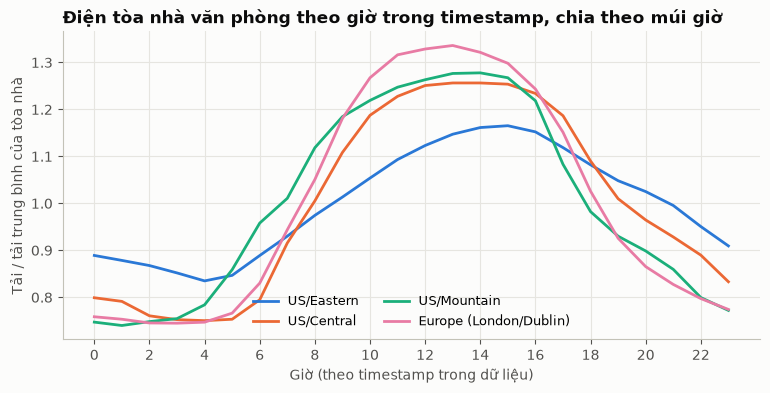

region,Europe (London/Dublin),US/Central,US/Eastern,US/Mountain
giờ đỉnh,13,13,15,14


In [21]:
REGIONS = ["US/Eastern", "US/Central", "US/Mountain", "US/Pacific", "Europe (London/Dublin)"]
office = (
    meters.filter("meter_type = 'electricity' AND meter_reading > 0")
    .join(meta.filter("primaryspaceusage = 'Office'").select("building_id", "site_id"), "building_id")
    .join(site_region.select("site_id", "region"), "site_id")
)
# Normalize each building by its own mean so big buildings don't dominate the profile.
b_mean = office.groupBy("building_id").agg(F.avg("meter_reading").alias("b_mean"))
office_profile = (
    office.join(b_mean, "building_id")
    .withColumn("load", F.col("meter_reading") / F.col("b_mean"))
    .withColumn("hour", F.hour("timestamp"))
    .groupBy("region", "hour").agg(F.avg("load").alias("load"))
    .toPandas()
    .pivot(index="hour", columns="region", values="load")
)
# Keep the fixed region order (stable colors); skip regions with no office buildings.
regions = [r for r in REGIONS if r in office_profile.columns]
print("Khu vực không có tòa nhà văn phòng:", [r for r in REGIONS if r not in regions])

fig, ax = plt.subplots()
for i, region in enumerate(REGIONS):
    if region not in regions:
        continue
    ax.plot(office_profile.index, office_profile[region], color=SERIES[i], label=region)
ax.set_title("Điện tòa nhà văn phòng theo giờ trong timestamp, chia theo múi giờ")
ax.set_xlabel("Giờ (theo timestamp trong dữ liệu)")
ax.set_ylabel("Tải / tải trung bình của tòa nhà")
ax.set_xticks(range(0, 24, 2))
ax.legend(ncol=2, fontsize=9, loc="lower center")
plt.show()
office_profile.idxmax().rename("giờ đỉnh").to_frame().T

## 7. Quy luật tiêu thụ

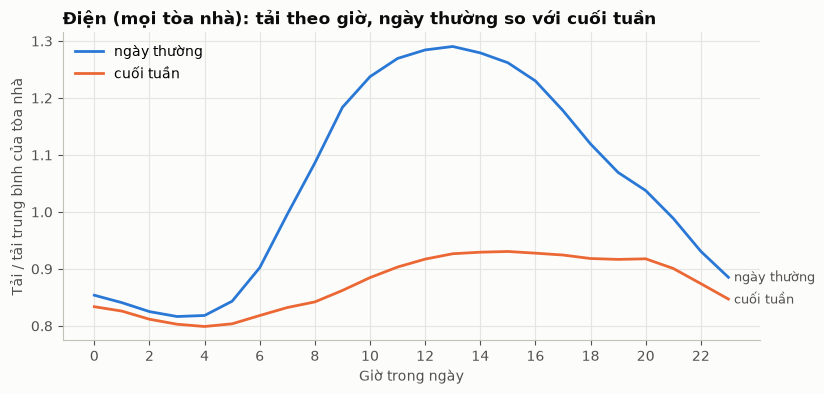

In [22]:
elec = meters.filter("meter_type = 'electricity' AND meter_reading > 0")
e_mean = elec.groupBy("building_id").agg(F.avg("meter_reading").alias("b_mean"))
weekly = (
    elec.join(e_mean, "building_id")
    .withColumn("load", F.col("meter_reading") / F.col("b_mean"))
    .withColumn("hour", F.hour("timestamp"))
    .withColumn("day_type", F.when(F.dayofweek("timestamp").isin(1, 7), "cuối tuần").otherwise("ngày thường"))
    .groupBy("day_type", "hour").agg(F.avg("load").alias("load"))
    .toPandas()
    .pivot(index="hour", columns="day_type", values="load")
)
fig, ax = plt.subplots()
for i, col in enumerate(["ngày thường", "cuối tuần"]):
    ax.plot(weekly.index, weekly[col], color=SERIES[i], label=col)
    ax.annotate(col, (23, weekly[col].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color="#52514e", fontsize=9, va="center")
ax.set_title("Điện (mọi tòa nhà): tải theo giờ, ngày thường so với cuối tuần")
ax.set_xlabel("Giờ trong ngày")
ax.set_ylabel("Tải / tải trung bình của tòa nhà")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc="upper left")
plt.show()

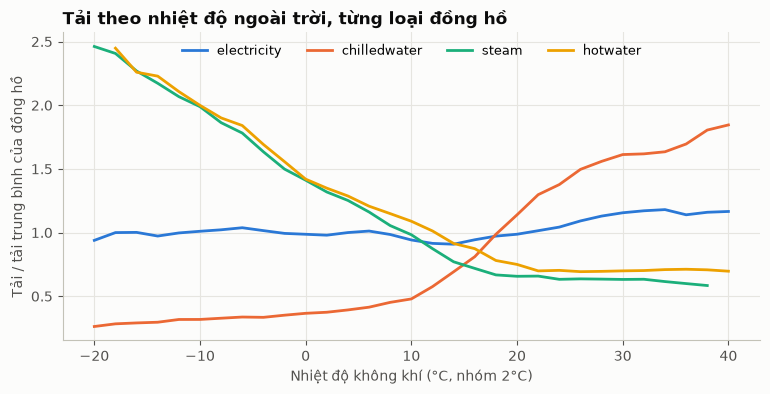

In [23]:
# Nhiệt độ ảnh hưởng thế nào tới từng loại năng lượng? (đây là lý do đưa nhiệt độ vào feature)
TEMP_METERS = ["electricity", "chilledwater", "steam", "hotwater"]
m = meters.filter(F.col("meter_type").isin(TEMP_METERS) & (F.col("meter_reading") > 0))
m_mean = m.groupBy("meter_type", "building_id").agg(F.avg("meter_reading").alias("b_mean"))
temp_effect = (
    m.join(m_mean, ["meter_type", "building_id"])
    .withColumn("load", F.col("meter_reading") / F.col("b_mean"))
    .join(meta.select("building_id", "site_id"), "building_id")
    .join(F.broadcast(weather.select("site_id", "timestamp", "airTemperature")), ["site_id", "timestamp"])
    .filter(F.col("airTemperature").between(-20, 40))
    .withColumn("temp_bin", F.floor(F.col("airTemperature") / 2) * 2)
    .groupBy("meter_type", "temp_bin").agg(F.avg("load").alias("load"), F.count("*").alias("n"))
    .filter("n >= 1000")
    .toPandas()
    .pivot(index="temp_bin", columns="meter_type", values="load")[TEMP_METERS]
)
fig, ax = plt.subplots()
for i, col in enumerate(TEMP_METERS):
    ax.plot(temp_effect.index, temp_effect[col], color=SERIES[i], label=col)
ax.set_title("Tải theo nhiệt độ ngoài trời, từng loại đồng hồ")
ax.set_xlabel("Nhiệt độ không khí (°C, nhóm 2°C)")
ax.set_ylabel("Tải / tải trung bình của đồng hồ")
ax.legend(loc="upper center", ncol=4, fontsize=9)
plt.show()

## 8. Tổng hợp: phát hiện và quyết định làm sạch cho Silver

Các con số dưới đây lấy từ kết quả chạy notebook trên **toàn bộ 53.561.832 số đo**. Ngưỡng nào đổi thì phải chạy lại notebook và cập nhật bảng này.

### 8.1. Phát hiện chính

| # | Phát hiện | Bằng chứng (mục) |
|---|---|---|
| F1 | **Timestamp là giờ địa phương, không phải UTC.** Nhiệt độ cao nhất trong ngày rơi vào 14–15h ở mọi khu vực (Mỹ 4 múi giờ và châu Âu); điện văn phòng đạt đỉnh 13–15h ở mọi khu vực. Nếu là UTC, đỉnh của châu Âu phải sớm hơn Mỹ 5–8 tiếng. | 6 |
| F2 | Mỗi site có đúng **1 múi giờ** → chuyển sang UTC theo site được. | 2 |
| F3 | **Không có giá trị âm** ở cả 8 loại đồng hồ. | 1, 4.1 |
| F4 | **29 đồng hồ trống hoàn toàn** (100% null): steam 19, chilledwater 5, electricity 2, water 2, solar 1. | 3 |
| F5 | Điện: 1.445/1.578 đồng hồ thiếu ≤ 10%; **62 đồng hồ thiếu 50–<100%**. Site **Swan** thiếu ~50% (có vẻ chỉ có dữ liệu 1 năm). | 3 |
| F6 | **Flatline** (giá trị đứng yên) rất đáng kể: với điện, 11,2% số giờ nằm trong đoạn đứng yên ≥ 24h. Có một cụm rõ ở **24–47h với giá trị khác 0** (3,5%), dấu hiệu đồng hồ chỉ ghi **theo ngày** rồi rải đều ra 24 giờ, nên không có quy luật theo giờ. | 4.2 |
| F7 | Số 0 kéo dài là bình thường với một số loại đồng hồ: irrigation 85,8% là 0, water 51%, gas 39%, hotwater 35% (tắt theo mùa). Với điện, chỉ 4,4% là 0, và 22 tòa nhà có trên 50% số 0. | 1, 4.2 |
| F8 | **Outlier do lỗi đồng hồ:** một số đồng hồ có giá trị lớn nhất gấp 60–130 lần p99 của chính nó (ví dụ `Bull_education_Dottie`: p99 = 1.655, max = 221.228). | 4.3 |
| F9 | Thời tiết: `airTemperature` chỉ thiếu 0,04%, `dewTemperature` 0,10%; nhưng `cloudCoverage` thiếu 52%, `precipDepth1HR` 40%, `precipDepth6HR` 95%. Site Crow, Moose thiếu 684 giờ; Cockatoo thiếu 569 giờ. Không có (site, giờ) trùng. | 5 |
| F10 | Metadata: **21 tòa nhà thiếu `primary_use`, đều ở site Swan**; `sqft` đầy đủ; `lat/lng` thiếu 237 (không dùng). | 2 |
| F11 | Quy luật rõ: ngày thường đỉnh ~1,29× trung bình lúc 13h, cuối tuần phẳng ~0,93×. Nhiệt độ: chilledwater **tăng mạnh** khi nóng, steam/hotwater **giảm** khi nóng, điện gần như phẳng. | 7 |

### 8.2. Quyết định làm sạch cho `preprocess.py`

| # | Quyết định | Lý do |
|---|---|---|
| D1 | Xoay 8 bảng đồng hồ sang dạng long, ép `meter_reading` về `double`. | F4 |
| D2 | Bỏ dòng `meter_reading` null; vẫn giữ luật **bỏ số âm** để phòng dữ liệu mới. | F3 |
| D3 | Bỏ đoạn **giá trị khác 0 đứng yên ≥ 24 giờ** (mọi loại đồng hồ). | F6: đồng hồ ghi theo ngày hoặc bị treo, không có quy luật theo giờ |
| D4 | Bỏ đoạn **giá trị 0 kéo dài ≥ 24 giờ, chỉ với điện**. Các loại khác giữ số 0. | F7: tòa nhà không thể mất điện cả ngày; còn nước, gas, tưới tiêu tắt theo mùa là thật |
| D5 | Bỏ giá trị **> 10 × p99** của chính đồng hồ đó. | F8: gấp hàng chục lần là lỗi đồng hồ, giữ lại sẽ làm lệch model. Bất thường thật (cỡ +28%) vẫn còn nguyên |
| D6 | Sau D2–D5, **loại đồng hồ còn dưới 50% số giờ** (< 8.772 giờ). | F5: không đủ dữ liệu để học quy luật |
| D7 | Thời tiết: chỉ dùng `airTemperature`, `dewTemperature`; đổi tên theo schema; **nội suy tuyến tính theo thời gian trong từng site** cho khoảng trống ≤ 6 giờ; giờ còn thiếu thì bỏ dòng số đo tương ứng. | F9 |
| D8 | **Join theo giờ địa phương** (số đo ⋈ metadata theo `building_id`, ⋈ thời tiết theo `site_id` + `timestamp`), **sau đó** chuyển `timestamp` sang UTC bằng `to_utc_timestamp(timestamp, timezone)` của site. Kiểm tra trùng `(building_id, meter_type, timestamp)` sau khi chuyển, vì giờ đổi mùa (DST) có thể sinh giờ trùng hoặc giờ không tồn tại. | F1, F2 |
| D9 | `hour_of_day`, `day_of_week`, `is_weekend` tính từ **giờ địa phương** (trước khi chuyển UTC), vì thói quen dùng điện theo giờ địa phương. | F1, F11 |
| D10 | `primary_use` thiếu → gán `"Unknown"` (giữ 21 tòa nhà ở Swan, đúng tinh thần dùng toàn bộ dữ liệu). | F10 |
| D11 | Đổi tên cột theo hợp đồng: `primaryspaceusage` → `primary_use`, `sqft` → `square_feet`, `airTemperature` → `air_temperature`, `dewTemperature` → `dew_temperature`. | Schema mục 3 `docs/TASKS.md` |

### 8.3. Đã chốt sau EDA

- **Phạm vi đồng hồ:** Silver gồm **cả 8 loại**, thêm cột `meter_type` vào schema (F11: mỗi loại phản ứng với nhiệt độ ngược nhau, nên model bắt buộc phải biết loại đồng hồ). `solar` là đồng hồ **phát** điện (4 đồng hồ sau làm sạch): giữ trong Silver, không dùng cho phát hiện bất thường.
- **Kết quả chạy `preprocess.py`:** 53.561.832 → 45.900.387 dòng (bảng số dòng từng bước ở `data_pipeline/README.md`). Site **Swan** bị loại toàn bộ ở D6 vì chỉ có dữ liệu năm 2017 (không có gì để train trên 2016).


In [24]:
runs.unpersist()
spikes.unpersist()
spark.stop()